# 05 - Dataset Variability Analysis

## Objective

Measure the variability/diversity of the WLASL dataset to understand:
1. **Why the model overfits**: Is there enough diversity in the training data?
2. **What augmentation should target**: Where is diversity lacking?
3. **Baseline for comparison**: Metrics to compare before/after augmentation

## Metrics We'll Compute

### 1. Intra-class Variance
How different are videos of the **same word**?
- Low variance = videos are too similar (bad for learning)
- High variance = diverse examples (good for generalization)

### 2. Inter-class Distance
How different are videos of **different words**?
- Low distance = classes overlap (hard to distinguish)
- High distance = classes are separable (easier task)

### 3. Fisher's Discriminant Ratio
Ratio of inter-class to intra-class variance:
- `FDR = inter_class_variance / intra_class_variance`
- Higher = better separability

### 4. Visualization
- t-SNE/UMAP projection of video features
- Shows how well classes cluster

In [20]:
# Mount Drive (for Colab)
from google.colab import drive
drive.mount('/content/drive')

!pip install umap-learn

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0. Environment Setup

In [21]:
import os
from pathlib import Path

# Dataset location
ZIP_LOCAL = Path("/content/wlasl30_augmented.zip")
DATASET_ROOT = Path("/content/wlasl30_augmented")

# Unzip if needed
if not DATASET_ROOT.exists():
    if ZIP_LOCAL.exists():
        print(f"📦 Extracting {ZIP_LOCAL}...")
        !unzip -q {ZIP_LOCAL} -d /content/
        print("✅ Done.")
    else:
        raise FileNotFoundError(f"Upload {ZIP_LOCAL} first!")
else:
    print("✅ Dataset ready.")

# Results directory
RESULTS_DIR = Path("/content/drive/MyDrive/tfg/analysis/variability_augmented")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"💾 Results will be saved to: {RESULTS_DIR}")

📦 Extracting /content/wlasl30_augmented.zip...
✅ Done.
💾 Results will be saved to: /content/drive/MyDrive/tfg/analysis/variability_augmented


In [22]:
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from scipy.spatial.distance import pdist, squareform
from scipy.stats import entropy
from collections import defaultdict
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

# Try to import UMAP (optional, better than t-SNE for large datasets)
try:
    from umap import UMAP
    HAS_UMAP = True
    print("✅ UMAP available")
except ImportError:
    HAS_UMAP = False
    print("⚠️ UMAP not installed. Using t-SNE instead.")
    print("   Install with: pip install umap-learn")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nUsing device: {device}")

✅ UMAP available

Using device: cuda


## 1. Load Dataset and Extract Features

We'll use a pre-trained ResNet18 to extract features from each video.
For each video, we:
1. Sample frames uniformly
2. Extract CNN features for each frame
3. Average features across frames → single 512-dim vector per video

In [23]:
# ImageNet normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

In [24]:
class FeatureExtractor(nn.Module):
    """ResNet18 feature extractor (removes classification head)."""

    def __init__(self):
        super().__init__()
        resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.features = nn.Sequential(*list(resnet.children())[:-1])  # Remove FC
        self.feature_dim = 512

    def forward(self, x):
        # x: [B, 3, 224, 224]
        features = self.features(x)  # [B, 512, 1, 1]
        return features.squeeze(-1).squeeze(-1)  # [B, 512]

# Load model
feature_extractor = FeatureExtractor().to(device)
feature_extractor.eval()
print(f"Feature extractor ready (output dim: {feature_extractor.feature_dim})")

Feature extractor ready (output dim: 512)


In [25]:
def load_video_frames(video_dir: Path, max_frames: int = 16) -> torch.Tensor:
    """Load and sample frames from a video directory."""
    frame_files = sorted(video_dir.glob("*.jpg"))

    if len(frame_files) == 0:
        return None

    # Uniform sampling
    if len(frame_files) > max_frames:
        indices = np.linspace(0, len(frame_files) - 1, max_frames, dtype=int)
        frame_files = [frame_files[i] for i in indices]

    frames = []
    for fp in frame_files:
        img = Image.open(fp).convert("RGB")
        frames.append(transform(img))

    return torch.stack(frames)  # [T, 3, 224, 224]


@torch.no_grad()
def extract_video_features(video_dir: Path, model: nn.Module, max_frames: int = 16) -> np.ndarray:
    """
    Extract features from a video.
    Returns mean feature vector across all frames.
    """
    frames = load_video_frames(video_dir, max_frames)
    if frames is None:
        return None

    frames = frames.to(device)
    features = model(frames)  # [T, 512]

    # Mean pooling across time
    mean_features = features.mean(dim=0)  # [512]

    return mean_features.cpu().numpy()

In [26]:
def extract_all_features(dataset_root: Path, split: str = "train"):
    """
    Extract features for all videos in a split.

    Returns:
        features: np.ndarray [N, 512] - Feature vectors
        labels: list[int] - Class labels
        glosses: list[str] - Word names
        video_paths: list[Path] - Video directories
    """
    # Load metadata
    with open(dataset_root / "metadata.json", "r") as f:
        metadata = json.load(f)
    gloss_to_idx = metadata["gloss_to_idx"]
    idx_to_gloss = {v: k for k, v in gloss_to_idx.items()}

    split_dir = dataset_root / split

    features_list = []
    labels_list = []
    glosses_list = []
    paths_list = []

    # Iterate through all classes
    all_videos = []
    for gloss_dir in sorted(split_dir.iterdir()):
        if not gloss_dir.is_dir():
            continue
        gloss = gloss_dir.name
        if gloss not in gloss_to_idx:
            continue
        label = gloss_to_idx[gloss]

        for video_dir in sorted(gloss_dir.iterdir()):
            if video_dir.is_dir():
                all_videos.append((video_dir, label, gloss))

    print(f"Extracting features from {len(all_videos)} videos...")

    for video_dir, label, gloss in tqdm(all_videos):
        feat = extract_video_features(video_dir, feature_extractor)
        if feat is not None:
            features_list.append(feat)
            labels_list.append(label)
            glosses_list.append(gloss)
            paths_list.append(video_dir)

    features = np.stack(features_list)
    print(f"Extracted features shape: {features.shape}")

    return features, labels_list, glosses_list, paths_list, idx_to_gloss

In [27]:
# Extract features for train and val splits
print("=" * 60)
print("EXTRACTING FEATURES")
print("=" * 60)

print("\n📊 Training set:")
train_features, train_labels, train_glosses, train_paths, idx_to_gloss = extract_all_features(
    DATASET_ROOT, split="train"
)

print("\n📊 Validation set:")
val_features, val_labels, val_glosses, val_paths, _ = extract_all_features(
    DATASET_ROOT, split="val"
)

EXTRACTING FEATURES

📊 Training set:
Extracting features from 980 videos...


  0%|          | 0/980 [00:00<?, ?it/s]

Extracted features shape: (980, 512)

📊 Validation set:
Extracting features from 57 videos...


  0%|          | 0/57 [00:00<?, ?it/s]

Extracted features shape: (57, 512)


## 2. Compute Variability Metrics

In [28]:
def compute_intra_class_variance(features: np.ndarray, labels: list) -> dict:
    """
    Compute variance within each class.

    High intra-class variance = diverse examples (good)
    Low intra-class variance = similar examples (bad for generalization)
    """
    labels = np.array(labels)
    unique_labels = np.unique(labels)

    variances = {}
    for label in unique_labels:
        class_features = features[labels == label]
        if len(class_features) > 1:
            # Variance across samples for each feature dimension, then mean
            var = np.var(class_features, axis=0).mean()
        else:
            var = 0.0
        variances[int(label)] = float(var)

    return variances


def compute_inter_class_distance(features: np.ndarray, labels: list) -> float:
    """
    Compute average distance between class centroids.

    High inter-class distance = classes are well separated (good)
    Low inter-class distance = classes overlap (hard to classify)
    """
    labels = np.array(labels)
    unique_labels = np.unique(labels)

    # Compute centroids
    centroids = []
    for label in unique_labels:
        class_features = features[labels == label]
        centroid = class_features.mean(axis=0)
        centroids.append(centroid)

    centroids = np.stack(centroids)

    # Compute pairwise distances between centroids
    distances = pdist(centroids, metric='euclidean')

    return float(distances.mean())


def compute_fisher_discriminant_ratio(features: np.ndarray, labels: list) -> float:
    """
    Fisher's Discriminant Ratio: inter-class variance / intra-class variance

    Higher = better class separability
    """
    labels = np.array(labels)
    unique_labels = np.unique(labels)

    # Global mean
    global_mean = features.mean(axis=0)

    # Compute inter-class variance (variance of class means around global mean)
    class_means = []
    class_sizes = []
    for label in unique_labels:
        class_features = features[labels == label]
        class_means.append(class_features.mean(axis=0))
        class_sizes.append(len(class_features))

    class_means = np.stack(class_means)

    # Inter-class variance (between-class scatter)
    inter_var = np.var(class_means, axis=0).mean()

    # Intra-class variance (within-class scatter)
    intra_vars = compute_intra_class_variance(features, labels)
    intra_var = np.mean(list(intra_vars.values()))

    if intra_var == 0:
        return float('inf')

    return float(inter_var / intra_var)


def compute_samples_per_class(labels: list) -> dict:
    """Count samples per class."""
    counts = defaultdict(int)
    for label in labels:
        counts[label] += 1
    return dict(counts)

In [29]:
# Compute metrics for training set
print("=" * 60)
print("VARIABILITY METRICS (Training Set)")
print("=" * 60)

# Samples per class
samples_per_class = compute_samples_per_class(train_labels)
print(f"\n📊 Samples per class:")
print(f"   Min: {min(samples_per_class.values())}")
print(f"   Max: {max(samples_per_class.values())}")
print(f"   Mean: {np.mean(list(samples_per_class.values())):.1f}")
print(f"   Std: {np.std(list(samples_per_class.values())):.1f}")

# Intra-class variance
intra_variances = compute_intra_class_variance(train_features, train_labels)
mean_intra_var = np.mean(list(intra_variances.values()))
print(f"\n📊 Intra-class variance:")
print(f"   Mean: {mean_intra_var:.4f}")
print(f"   Min: {min(intra_variances.values()):.4f}")
print(f"   Max: {max(intra_variances.values()):.4f}")

# Inter-class distance
inter_distance = compute_inter_class_distance(train_features, train_labels)
print(f"\n📊 Inter-class distance:")
print(f"   Mean centroid distance: {inter_distance:.4f}")

# Fisher's Discriminant Ratio
fdr = compute_fisher_discriminant_ratio(train_features, train_labels)
print(f"\n📊 Fisher's Discriminant Ratio:")
print(f"   FDR = {fdr:.4f}")
if fdr < 1:
    print(f"   ⚠️ FDR < 1: Intra-class variance > Inter-class variance")
    print(f"      Classes are overlapping! Hard to distinguish.")
else:
    print(f"   ✅ FDR > 1: Classes are reasonably separable")

VARIABILITY METRICS (Training Set)

📊 Samples per class:
   Min: 16
   Max: 48
   Mean: 32.7
   Std: 8.6

📊 Intra-class variance:
   Mean: 0.1601
   Min: 0.1287
   Max: 0.1919

📊 Inter-class distance:
   Mean centroid distance: 4.2567

📊 Fisher's Discriminant Ratio:
   FDR = 0.1100
   ⚠️ FDR < 1: Intra-class variance > Inter-class variance
      Classes are overlapping! Hard to distinguish.


In [30]:
# Detailed per-class analysis
print("\n" + "=" * 60)
print("PER-CLASS ANALYSIS")
print("=" * 60)

# Create DataFrame-like structure for display
class_stats = []
for label in sorted(intra_variances.keys()):
    gloss = idx_to_gloss[label]
    n_samples = samples_per_class[label]
    variance = intra_variances[label]
    class_stats.append({
        'label': label,
        'word': gloss,
        'n_samples': n_samples,
        'intra_variance': variance
    })

# Sort by variance (lowest first = least diverse)
class_stats_sorted = sorted(class_stats, key=lambda x: x['intra_variance'])

print("\n🔴 Classes with LOWEST variance (least diverse, highest overfitting risk):")
for i, stat in enumerate(class_stats_sorted[:5]):
    print(f"   {i+1}. '{stat['word']}': variance={stat['intra_variance']:.4f}, samples={stat['n_samples']}")

print("\n🟢 Classes with HIGHEST variance (most diverse):")
for i, stat in enumerate(class_stats_sorted[-5:][::-1]):
    print(f"   {i+1}. '{stat['word']}': variance={stat['intra_variance']:.4f}, samples={stat['n_samples']}")


PER-CLASS ANALYSIS

🔴 Classes with LOWEST variance (least diverse, highest overfitting risk):
   1. 'chair': variance=0.1287, samples=20
   2. 'thanksgiving': variance=0.1363, samples=36
   3. 'thin': variance=0.1379, samples=44
   4. 'deaf': variance=0.1451, samples=28
   5. 'before': variance=0.1493, samples=48

🟢 Classes with HIGHEST variance (most diverse):
   1. 'walk': variance=0.1919, samples=36
   2. 'mother': variance=0.1836, samples=40
   3. 'finish': variance=0.1830, samples=24
   4. 'no': variance=0.1818, samples=32
   5. 'clothes': variance=0.1715, samples=16


## 3. Visualization

In [31]:
def plot_feature_space(features: np.ndarray, labels: list, idx_to_gloss: dict,
                       method: str = 'tsne', title: str = "Feature Space",
                       save_path: str = None):
    """
    Visualize feature space using dimensionality reduction.

    Args:
        method: 'tsne', 'umap', or 'pca'
    """
    print(f"Computing {method.upper()} projection...")

    if method == 'tsne':
        reducer = TSNE(n_components=2, random_state=42, perplexity=min(30, len(features)-1))
        coords = reducer.fit_transform(features)
    elif method == 'umap' and HAS_UMAP:
        reducer = UMAP(n_components=2, random_state=42, n_neighbors=min(15, len(features)-1))
        coords = reducer.fit_transform(features)
    else:  # PCA fallback
        reducer = PCA(n_components=2, random_state=42)
        coords = reducer.fit_transform(features)

    # Plot
    fig, ax = plt.subplots(figsize=(14, 10))

    unique_labels = sorted(set(labels))
    colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))

    for i, label in enumerate(unique_labels):
        mask = np.array(labels) == label
        gloss = idx_to_gloss[label]
        ax.scatter(coords[mask, 0], coords[mask, 1],
                   c=[colors[i]], label=gloss, alpha=0.7, s=60)

    ax.set_title(f"{title} ({method.upper()})")
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to: {save_path}")

    plt.show()

    return coords


FEATURE SPACE VISUALIZATION
Computing UMAP projection...
Saved to: /content/drive/MyDrive/tfg/analysis/variability_augmented/feature_space_train_before_aug.png


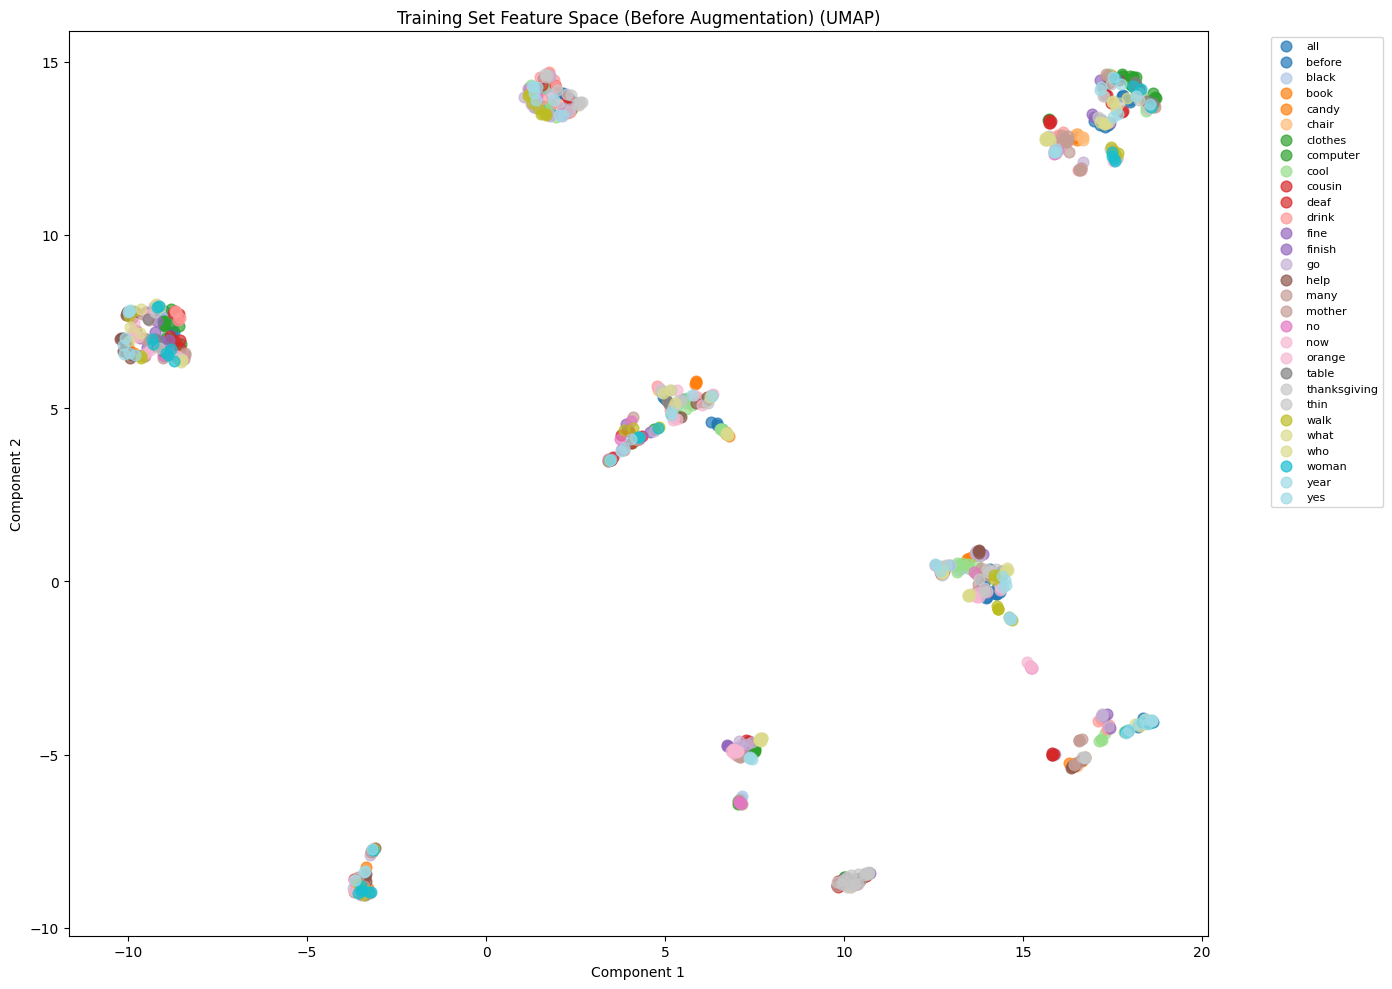

In [32]:
# Visualize training set
print("\n" + "=" * 60)
print("FEATURE SPACE VISUALIZATION")
print("=" * 60)

train_coords = plot_feature_space(
    train_features, train_labels, idx_to_gloss,
    method='umap' if HAS_UMAP else 'tsne',
    title="Training Set Feature Space (Before Augmentation)",
    save_path=str(RESULTS_DIR / "feature_space_train_before_aug.png")
)

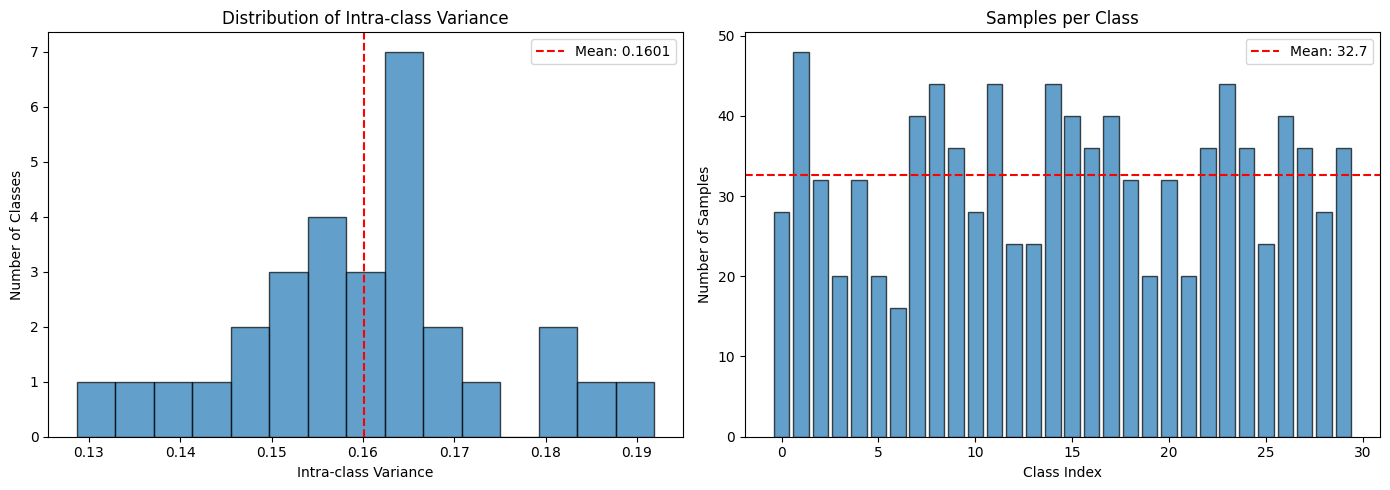

In [33]:
# Variance distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of intra-class variances
variances = list(intra_variances.values())
axes[0].hist(variances, bins=15, edgecolor='black', alpha=0.7)
axes[0].axvline(np.mean(variances), color='r', linestyle='--', label=f'Mean: {np.mean(variances):.4f}')
axes[0].set_xlabel('Intra-class Variance')
axes[0].set_ylabel('Number of Classes')
axes[0].set_title('Distribution of Intra-class Variance')
axes[0].legend()

# Samples per class
samples = [samples_per_class[i] for i in sorted(samples_per_class.keys())]
words = [idx_to_gloss[i] for i in sorted(samples_per_class.keys())]
axes[1].bar(range(len(samples)), samples, edgecolor='black', alpha=0.7)
axes[1].axhline(np.mean(samples), color='r', linestyle='--', label=f'Mean: {np.mean(samples):.1f}')
axes[1].set_xlabel('Class Index')
axes[1].set_ylabel('Number of Samples')
axes[1].set_title('Samples per Class')
axes[1].legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "variance_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

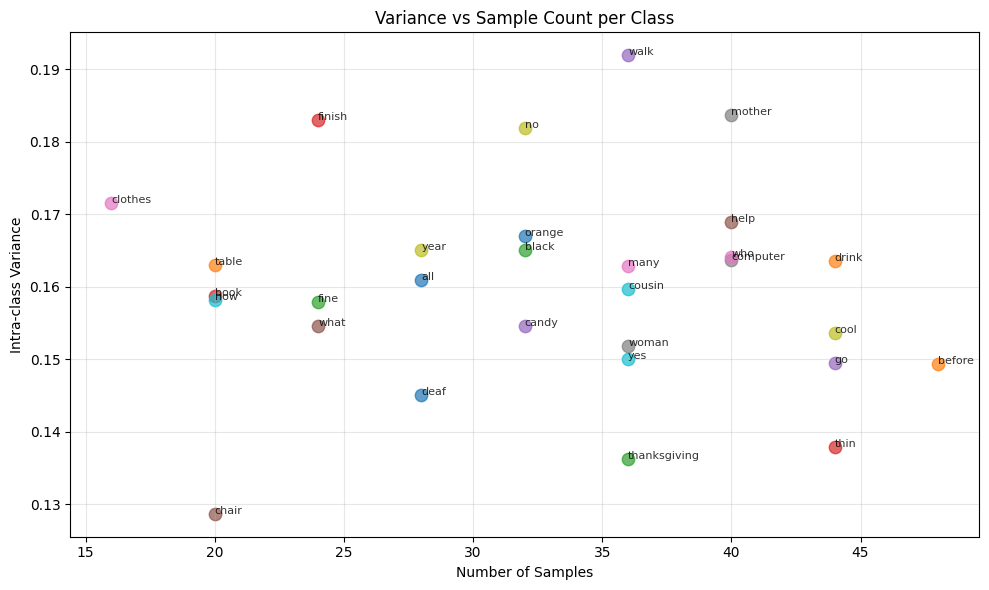

In [34]:
# Variance vs Number of Samples scatter plot
fig, ax = plt.subplots(figsize=(10, 6))

for stat in class_stats:
    ax.scatter(stat['n_samples'], stat['intra_variance'], s=80, alpha=0.7)
    ax.annotate(stat['word'], (stat['n_samples'], stat['intra_variance']),
                fontsize=8, alpha=0.8)

ax.set_xlabel('Number of Samples')
ax.set_ylabel('Intra-class Variance')
ax.set_title('Variance vs Sample Count per Class')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "variance_vs_samples.png", dpi=150, bbox_inches='tight')
plt.show()

## 4. Class Similarity Matrix

Which classes are most similar to each other? This helps understand potential confusion.

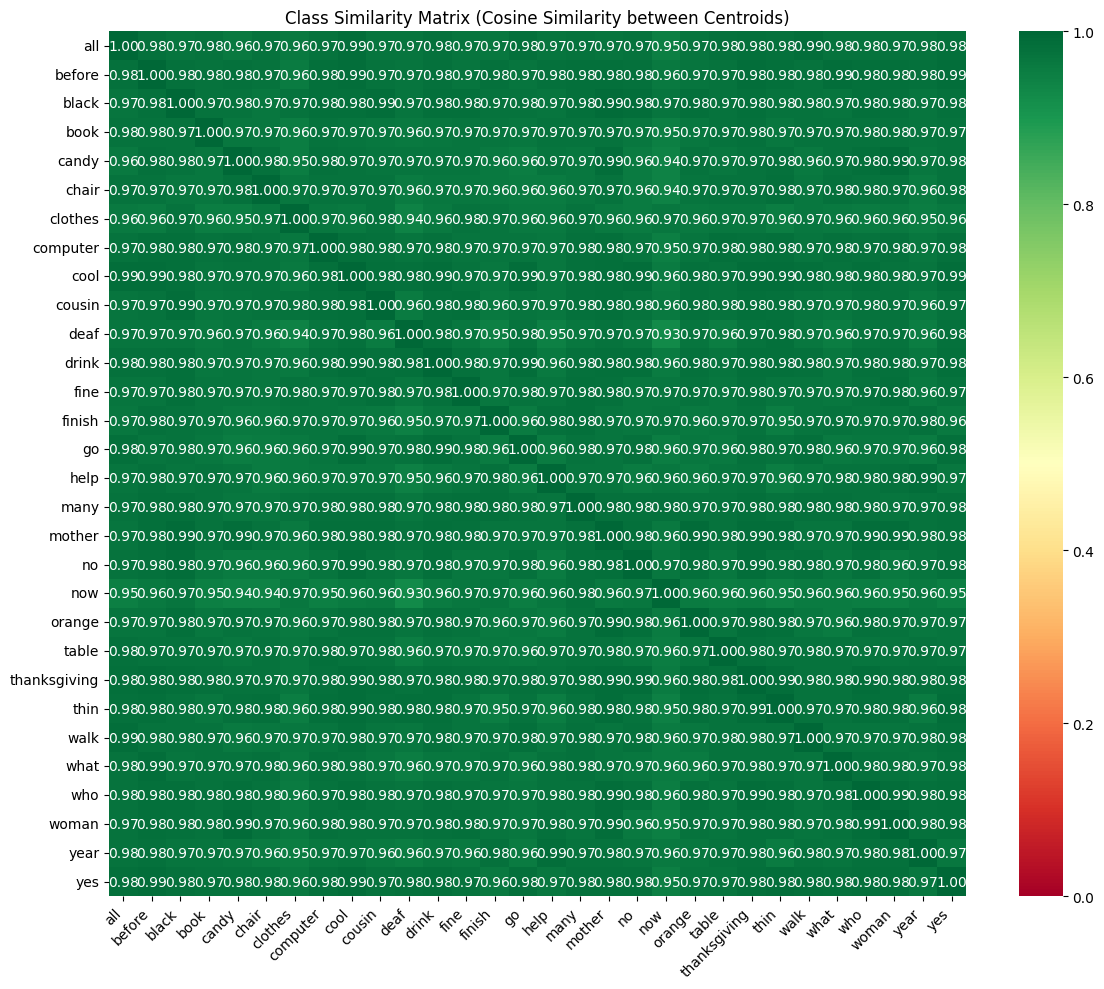

In [35]:
def compute_class_similarity_matrix(features: np.ndarray, labels: list):
    """
    Compute cosine similarity between class centroids.
    """
    labels = np.array(labels)
    unique_labels = sorted(set(labels))
    n_classes = len(unique_labels)

    # Compute centroids
    centroids = []
    for label in unique_labels:
        class_features = features[labels == label]
        centroid = class_features.mean(axis=0)
        # Normalize for cosine similarity
        centroid = centroid / (np.linalg.norm(centroid) + 1e-8)
        centroids.append(centroid)

    centroids = np.stack(centroids)

    # Cosine similarity matrix
    similarity = centroids @ centroids.T

    return similarity, unique_labels


# Compute and plot
similarity_matrix, labels_order = compute_class_similarity_matrix(train_features, train_labels)

fig, ax = plt.subplots(figsize=(12, 10))

class_names = [idx_to_gloss[l] for l in labels_order]

sns.heatmap(similarity_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
            xticklabels=class_names, yticklabels=class_names,
            vmin=0, vmax=1, ax=ax)
ax.set_title('Class Similarity Matrix (Cosine Similarity between Centroids)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(RESULTS_DIR / "class_similarity_matrix.png", dpi=150, bbox_inches='tight')
plt.show()

In [36]:
# Find most similar class pairs (potential confusion)
print("\n🔴 Most similar class pairs (highest confusion risk):")

# Get upper triangle of similarity matrix (excluding diagonal)
n = len(similarity_matrix)
pairs = []
for i in range(n):
    for j in range(i+1, n):
        pairs.append((similarity_matrix[i, j], labels_order[i], labels_order[j]))

pairs_sorted = sorted(pairs, key=lambda x: x[0], reverse=True)

for i, (sim, l1, l2) in enumerate(pairs_sorted[:10]):
    print(f"   {i+1}. '{idx_to_gloss[l1]}' ↔ '{idx_to_gloss[l2]}': similarity = {sim:.3f}")


🔴 Most similar class pairs (highest confusion risk):
   1. 'black' ↔ 'mother': similarity = 0.989
   2. 'candy' ↔ 'woman': similarity = 0.989
   3. 'mother' ↔ 'orange': similarity = 0.988
   4. 'cool' ↔ 'thanksgiving': similarity = 0.988
   5. 'cool' ↔ 'drink': similarity = 0.988
   6. 'before' ↔ 'cool': similarity = 0.988
   7. 'drink' ↔ 'go': similarity = 0.988
   8. 'cool' ↔ 'yes': similarity = 0.988
   9. 'cool' ↔ 'thin': similarity = 0.987
   10. 'thanksgiving' ↔ 'who': similarity = 0.987


## 5. Save Results for Comparison

In [37]:
# Compile all metrics
variability_report = {
    "dataset": "WLASL30",
    "split": "train",
    "augmentation": "none",
    "n_samples": len(train_features),
    "n_classes": len(set(train_labels)),
    "metrics": {
        "mean_intra_class_variance": float(mean_intra_var),
        "inter_class_distance": float(inter_distance),
        "fisher_discriminant_ratio": float(fdr),
        "samples_per_class": {
            "min": int(min(samples_per_class.values())),
            "max": int(max(samples_per_class.values())),
            "mean": float(np.mean(list(samples_per_class.values()))),
            "std": float(np.std(list(samples_per_class.values())))
        }
    },
    "per_class": {
        idx_to_gloss[stat['label']]: {
            "n_samples": stat['n_samples'],
            "intra_variance": stat['intra_variance']
        } for stat in class_stats
    }
}

# Save JSON
with open(RESULTS_DIR / "variability_baseline.json", "w") as f:
    json.dump(variability_report, f, indent=2)

print(f"\n✅ Results saved to: {RESULTS_DIR}")
print("\nFiles generated:")
for f in sorted(RESULTS_DIR.iterdir()):
    print(f"   - {f.name}")


✅ Results saved to: /content/drive/MyDrive/tfg/analysis/variability_augmented

Files generated:
   - class_similarity_matrix.png
   - feature_space_train_before_aug.png
   - variability_baseline.json
   - variance_distribution.png
   - variance_vs_samples.png


## 6. Summary and Recommendations

In [38]:
print("\n" + "=" * 60)
print("SUMMARY: DATASET VARIABILITY ANALYSIS")
print("=" * 60)

print(f"\n📊 Dataset: WLASL30 (Training Set)")
print(f"   Total videos: {len(train_features)}")
print(f"   Classes: {len(set(train_labels))}")
print(f"   Videos per class: {np.mean(list(samples_per_class.values())):.1f} ± {np.std(list(samples_per_class.values())):.1f}")

print(f"\n📈 Variability Metrics:")
print(f"   Mean Intra-class Variance: {mean_intra_var:.4f}")
print(f"   Inter-class Distance: {inter_distance:.4f}")
print(f"   Fisher's Discriminant Ratio: {fdr:.4f}")

print(f"\n🎯 Interpretation:")
if fdr < 1:
    print(f"   ⚠️ FDR < 1 indicates classes are OVERLAPPING")
    print(f"   → Videos of different words look too similar to the model")
    print(f"   → This explains the severe overfitting")
else:
    print(f"   ✅ FDR > 1 indicates reasonable class separation")

print(f"\n💡 Recommendations for Augmentation:")
print(f"   1. INCREASE intra-class variance:")
print(f"      - Spatial augmentation (crop, scale, rotation)")
print(f"      - Color augmentation (brightness, contrast, saturation)")
print(f"      - Temporal augmentation (speed variations, frame dropping)")
print(f"\n   2. Target classes with LOWEST variance (highest overfitting risk):")
for stat in class_stats_sorted[:3]:
    print(f"      - '{stat['word']}' (variance={stat['intra_variance']:.4f})")
print(f"\n   3. Expected impact of good augmentation:")
print(f"      - Intra-class variance should INCREASE (more diversity)")
print(f"      - FDR should remain similar or INCREASE (maintain separability)")

print("\n" + "=" * 60)
print("Run this notebook AGAIN after augmentation to compare!")
print("=" * 60)


SUMMARY: DATASET VARIABILITY ANALYSIS

📊 Dataset: WLASL30 (Training Set)
   Total videos: 980
   Classes: 30
   Videos per class: 32.7 ± 8.6

📈 Variability Metrics:
   Mean Intra-class Variance: 0.1601
   Inter-class Distance: 4.2567
   Fisher's Discriminant Ratio: 0.1100

🎯 Interpretation:
   ⚠️ FDR < 1 indicates classes are OVERLAPPING
   → Videos of different words look too similar to the model
   → This explains the severe overfitting

💡 Recommendations for Augmentation:
   1. INCREASE intra-class variance:
      - Spatial augmentation (crop, scale, rotation)
      - Color augmentation (brightness, contrast, saturation)
      - Temporal augmentation (speed variations, frame dropping)

   2. Target classes with LOWEST variance (highest overfitting risk):
      - 'chair' (variance=0.1287)
      - 'thanksgiving' (variance=0.1363)
      - 'thin' (variance=0.1379)

   3. Expected impact of good augmentation:
      - Intra-class variance should INCREASE (more diversity)
      - FDR shou